# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

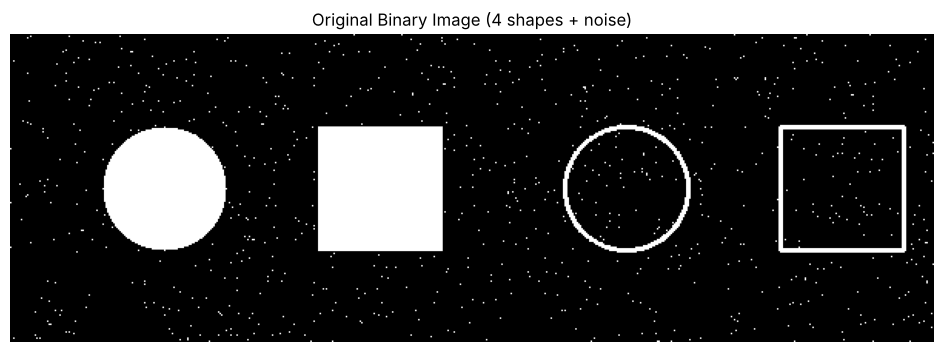

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



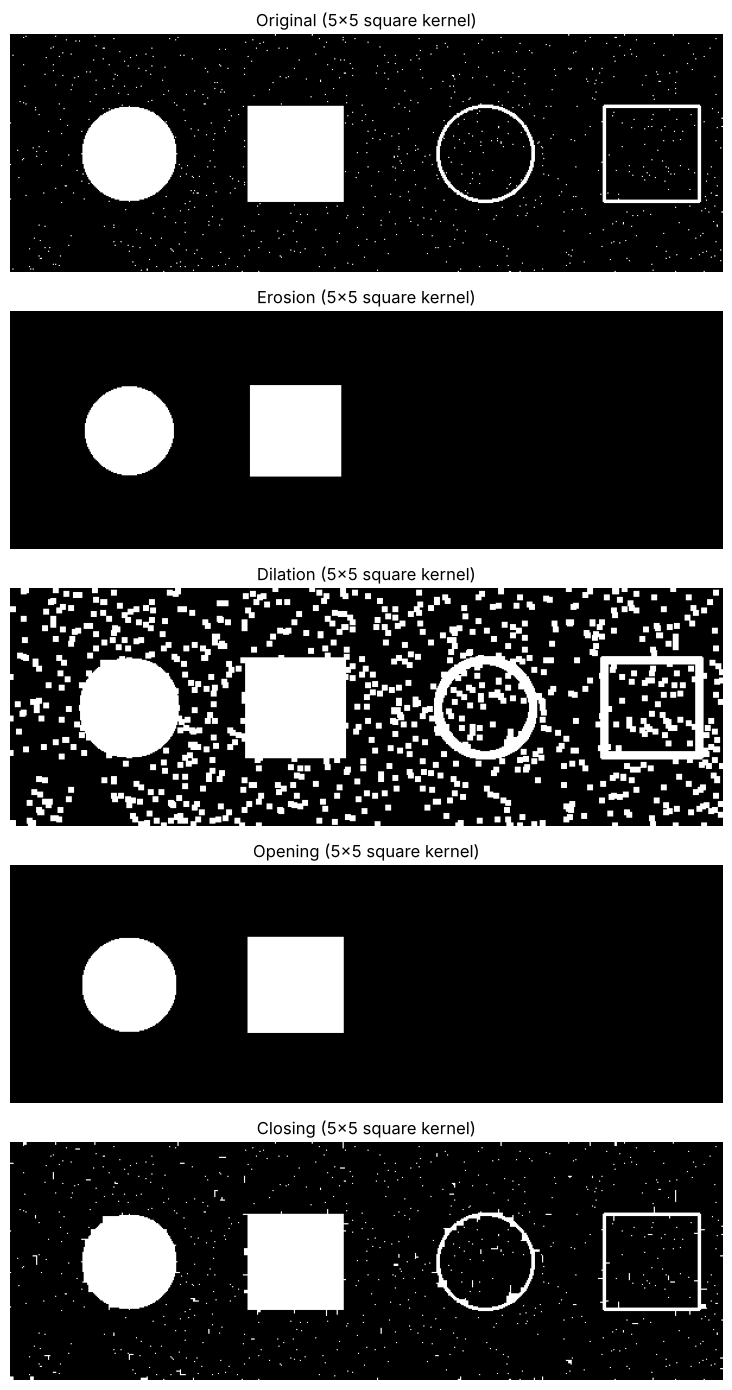

Original :  14165 white pixels
Erosion  :  10335 white pixels
Dilation :  35685 white pixels
Opening  :  11583 white pixels
Closing  :  14707 white pixels


In [4]:
# Assessment Task 1: apply the four operations with the 5x5 square kernel
erosion_sq  = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_sq = [image, erosion_sq, dilation_sq, opening_sq, closing_sq]
titles_sq  = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

plt.figure(figsize=(12, 14))
for i, (img, t) in enumerate(zip(results_sq, titles_sq)):
    plt.subplot(5, 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'{t} (5x5 square kernel)')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Count white pixels to quantify the effect of each operation
for img, t in zip(results_sq, titles_sq):
    print(f'{t:<9}: {np.count_nonzero(img):6d} white pixels')

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

Circular kernel (11x11):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


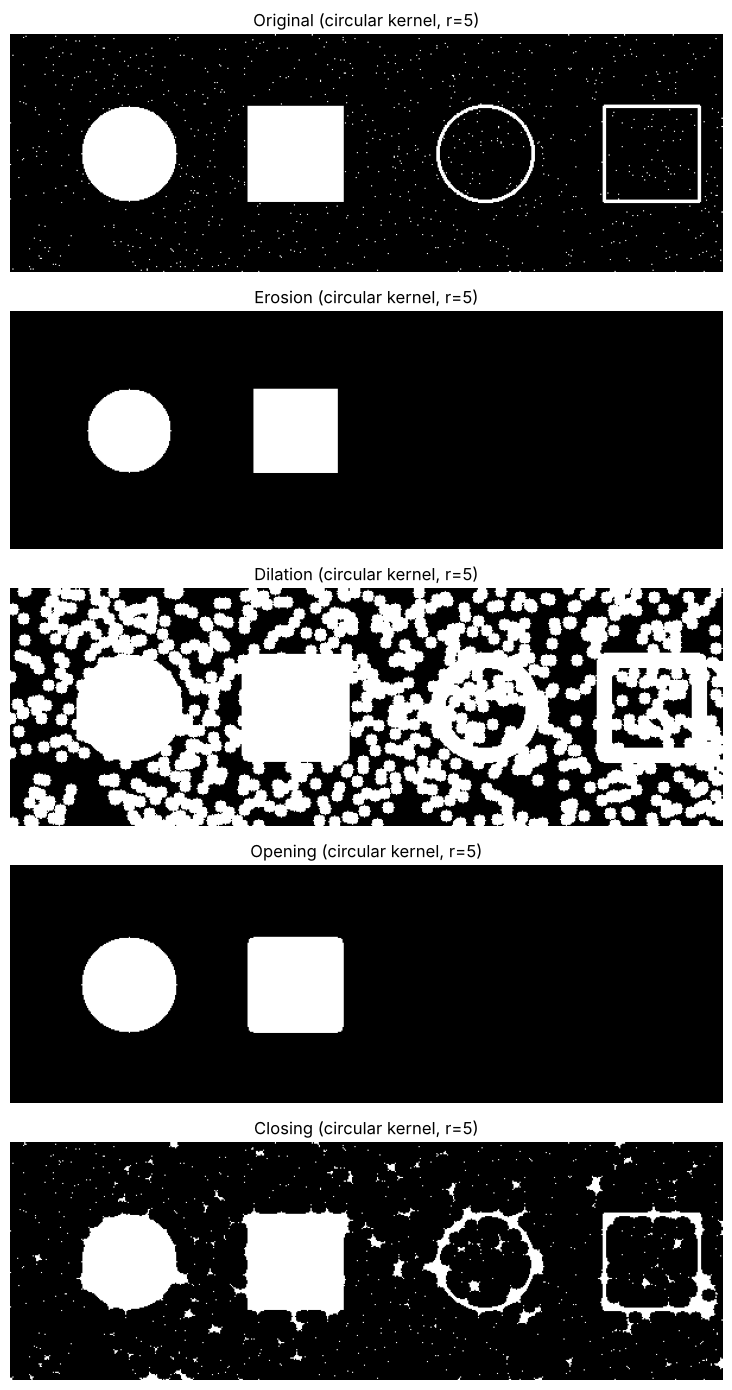

Original :  14165 white pixels
Erosion  :   8903 white pixels
Dilation :  67938 white pixels
Opening  :  11547 white pixels
Closing  :  17834 white pixels


In [6]:
# Assessment Task 2: apply the four operations with the circular kernel (radius = 5 -> 11x11)
print(f"Circular kernel ({circle_kernel.shape[0]}x{circle_kernel.shape[1]}):")
print(circle_kernel)

erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_c = [image, erosion_c, dilation_c, opening_c, closing_c]
titles_c  = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

plt.figure(figsize=(12, 14))
for i, (img, t) in enumerate(zip(results_c, titles_c)):
    plt.subplot(5, 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'{t} (circular kernel, r={radius})')
    plt.axis('off')
plt.tight_layout()
plt.show()

for img, t in zip(results_c, titles_c):
    print(f'{t:<9}: {np.count_nonzero(img):6d} white pixels')

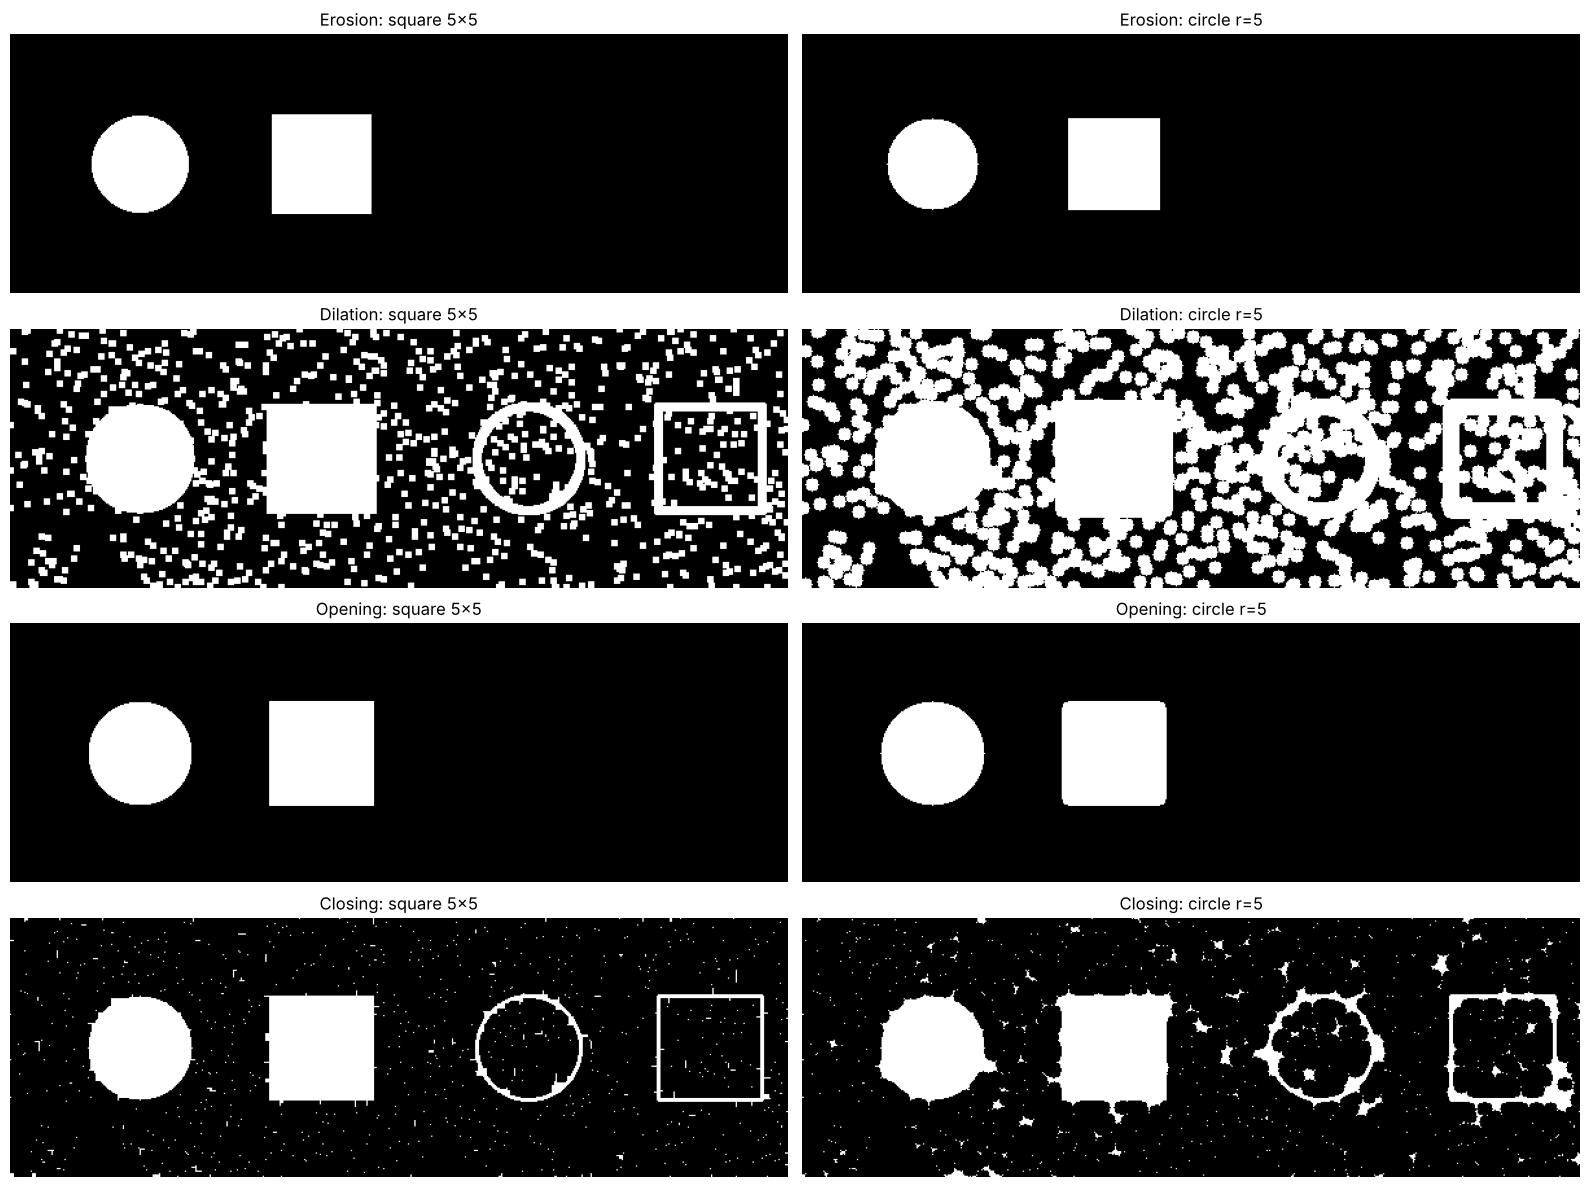

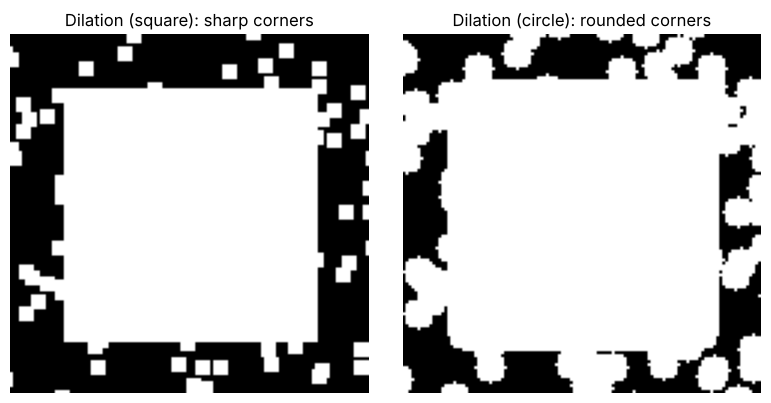

In [7]:
# Side-by-side comparison: square (left) vs circular (right)
ops = ['Erosion', 'Dilation', 'Opening', 'Closing']
plt.figure(figsize=(16, 12))
for i, op in enumerate(ops):
    plt.subplot(4, 2, 2 * i + 1)
    plt.imshow(results_sq[i + 1], cmap='gray'); plt.title(f'{op}: square 5x5'); plt.axis('off')
    plt.subplot(4, 2, 2 * i + 2)
    plt.imshow(results_c[i + 1], cmap='gray');  plt.title(f'{op}: circle r=5'); plt.axis('off')
plt.tight_layout()
plt.show()

# Zoom on the solid rectangle corners after dilation to show corner shape
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(dilation_sq[40:160, 180:300], cmap='gray'); plt.title('Dilation (square): sharp corners'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(dilation_c[40:160, 180:300], cmap='gray');  plt.title('Dilation (circle): rounded corners'); plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



###  Square kernel vs Circular kernel

Answer:

The main difference is the shape. The square kernel keeps the corners sharp, while the circular kernel makes them rounded. Also the circular kernel is bigger (11x11 vs 5x5), so its effect is stronger:

- Erosion: both kernels removed all the noise and the hollow circle and rectangle (because their lines are thin). The circular one made the solid shapes smaller than the square one.
- Dilation: the circular kernel made everything much thicker, and the noise dots joined together into big blobs.
- Opening: both removed the noise and kept the solid shapes almost the same size, but with the circular kernel the rectangle corners became round.
- Closing: with the square kernel the result looks close to the original. With the circular kernel the noise dots connected to each other and to the shapes.

So the square kernel is better when we want to keep straight edges and corners, and the circular kernel gives smoother and rounder results.
